# Ringdown Lab: when does ignoring the overtone matter?

**Question.** At what signal-to-noise ratio (SNR) does the bias from a slightly wrong model
(ignoring the overtone) become larger than the error caused by noise, when measuring a
ringing black hole?

After two black holes merge, the new black hole "rings" like a struck bell. The ringing is
a sum of **quasi-normal modes**: damped sinusoids. The loudest is the fundamental **220**
mode. Right after the peak there is also the **221 overtone**, which dies about three times
faster. If we fit only the 220 mode, the leftover overtone pushes our answer away from
the truth. That push is the **bias**. Noise also moves the answer around randomly; that is the
**noise error**. Noise error shrinks as the signal gets louder (higher SNR), but the bias does
not. So above some SNR the bias must win. This notebook finds that SNR.

In [1]:
import json
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Image, display

from ringdown_lab.qnm import qnm, REMNANT_MASS, REMNANT_SPIN
from ringdown_lab.signal import time_axis, two_mode
from ringdown_lab.noise import white_noise, snr, scale_to_snr
from ringdown_lab.fit import fit_two_mode

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()

## Check 1: mode frequencies and damping times

Berti, Cardoso & Will (2006) fits for a remnant with M = 62.7 solar masses and spin 0.68.
Expected: 220 ≈ 271.4 Hz, 3.76 ms; 221 ≈ 265.4 Hz, 1.24 ms.

In [2]:
f0, tau0 = qnm("220", REMNANT_MASS, REMNANT_SPIN)
f1, tau1 = qnm("221", REMNANT_MASS, REMNANT_SPIN)
print(f"220: f = {f0:.2f} Hz, tau = {tau0*1e3:.3f} ms")
print(f"221: f = {f1:.2f} Hz, tau = {tau1*1e3:.3f} ms")

220: f = 271.41 Hz, tau = 3.759 ms
221: f = 265.41 Hz, tau = 1.238 ms


## Check 2: the signal

Both modes with amplitude 1 and phase 0, so at t = 0 the signal is 1 + 1 = 2.

h(0) = 2.0


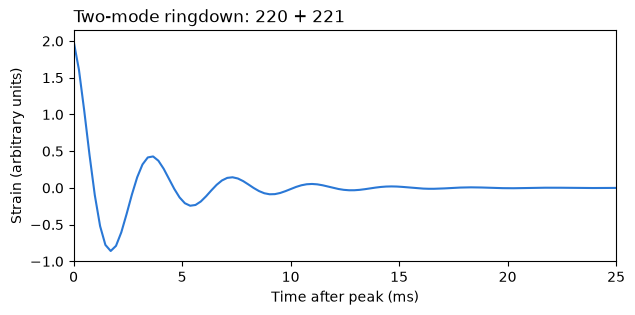

In [3]:
t = time_axis()
true = np.array([1, 0, f0, tau0, 1, 0, f1, tau1])
h = two_mode(t, *true)
print("h(0) =", h[0])

fig, ax = plt.subplots(figsize=(7, 3))
ax.plot(t * 1e3, h, color="#2a78d6", lw=1.5)
ax.set_xlim(0, 25)
ax.set_xlabel("Time after peak (ms)")
ax.set_ylabel("Strain (arbitrary units)")
ax.set_title("Two-mode ringdown: 220 + 221", loc="left")
plt.show()

## Check 3: noise and SNR

White noise should have standard deviation 1, and `scale_to_snr` should hit the target SNR.

noise std = 1.0001285040531447
SNR after scaling to 50 = 50.00000000000001


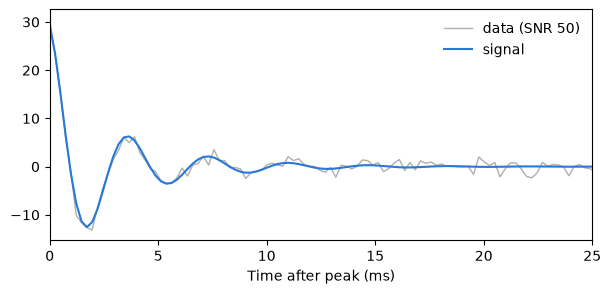

In [4]:
rng = np.random.default_rng(0)
print("noise std =", white_noise(100_000, 1.0, rng).std())
print("SNR after scaling to 50 =", snr(scale_to_snr(h, 50)))

data = scale_to_snr(h, 50) + white_noise(len(t), 1.0, rng)
fig, ax = plt.subplots(figsize=(7, 3))
ax.plot(t * 1e3, data, color="#b0afa9", lw=1, label="data (SNR 50)")
ax.plot(t * 1e3, scale_to_snr(h, 50), color="#2a78d6", lw=1.5, label="signal")
ax.set_xlim(0, 25)
ax.set_xlabel("Time after peak (ms)")
ax.legend(frameon=False)
plt.show()

## Check 4: a fit with no noise gets the right answer

If the fitting code is correct, fitting the clean signal must give back the true values,
even when we start 8-9% away.

In [5]:
start = true * np.array([1, 1, 1.08, 0.92, 1, 1, 0.93, 1.09])
params, ok = fit_two_mode(t, h, start)
for name, x, y in zip("a0 b0 f0 tau0 a1 b1 f1 tau1".split(), true, params):
    print(f"{name:5s} true {x:11.6g}   fit {y:11.6g}")

a0    true           1   fit           1
b0    true           0   fit -8.15128e-15
f0    true     271.413   fit     271.413
tau0  true  0.00375888   fit  0.00375888
a1    true           1   fit           1
b1    true           0   fit 3.02818e-14
f1    true     265.413   fit     265.413
tau1  true  0.00123762   fit  0.00123762


## Results

All numbers come from `python run_build.py` (N = 200 noise realisations per point),
saved in `results/results.json`.

In [6]:
res = json.loads((ROOT / "results" / "results.json").read_text())
print("Experiment A: two-mode fits")
print(f"{'SNR':>5} {'f221 error (Hz)':>16} {'Fisher (Hz)':>12} {'lost (%)':>9}")
for r in res["experiment_a"]["rows"]:
    print(f"{r['snr']:>5} {r['f221_error_hz']:>16.1f} {r['f221_fisher_hz']:>12.1f} {r['percent_lost']:>9.1f}")
print(f"log-log slope above SNR 50: {res['experiment_a']['slope_above_snr_50']:.2f}  (expected about -1)")
print()
print("Experiment B: fit only the 220 mode")
print(f"{'start (ms)':>10} {'bias tau220 (%)':>16} {'crossover SNR':>14}")
for r in res["experiment_b"]:
    print(f"{r['start_ms']:>10} {r['bias_percent']:>16.2f} {r['crossover_snr']:>14.1f}")

Experiment A: two-mode fits
  SNR  f221 error (Hz)  Fisher (Hz)  lost (%)
    8             85.3        558.1      40.5
   10             70.7        446.4      34.0
   15             95.7        297.6      36.5
   20             92.4        223.2      36.0
   30             67.7        148.8      36.5
   50            113.6         89.3      47.0
   80             52.2         55.8      32.0
  120             45.2         37.2      25.0
  200             21.0         22.3       5.0
  300             14.9         14.9       0.0
log-log slope above SNR 50: -1.11  (expected about -1)

Experiment B: fit only the 220 mode
start (ms)  bias tau220 (%)  crossover SNR
         0           -34.70            4.4
         1           -19.89           15.9
         2           -13.27           37.2
         3            -8.47           73.5
         4            -4.77          216.1
         6            -1.60         1311.0
         8            -0.53        10420.9


### Experiment A: can we measure the overtone?

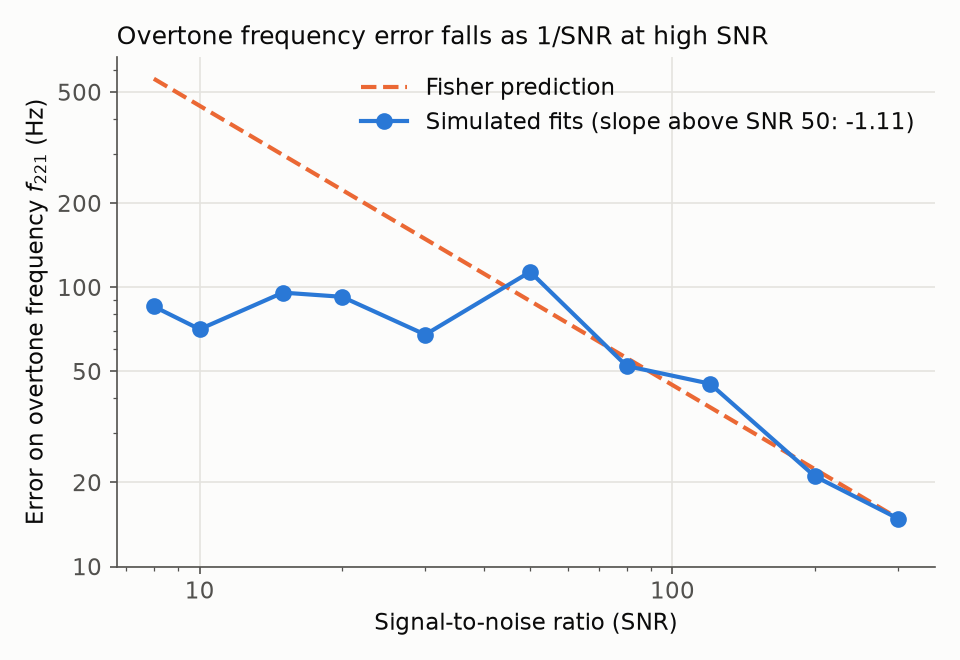

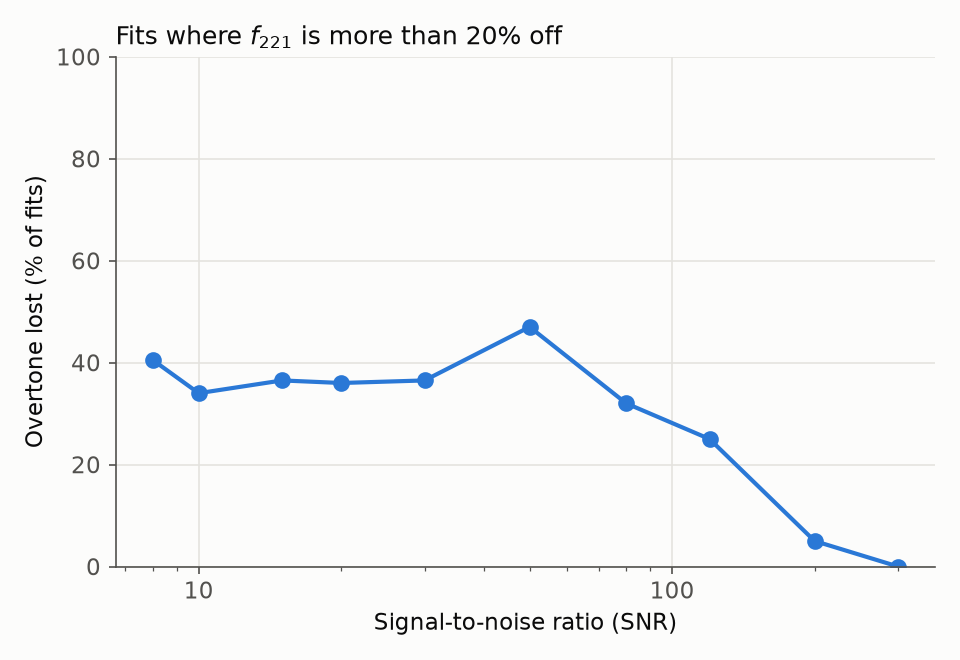

In [7]:
display(Image(ROOT / "figures" / "01_overtone_error_vs_snr.png"))
display(Image(ROOT / "figures" / "02_overtone_lost_vs_snr.png"))

### Experiment B: bias from ignoring the overtone vs noise error

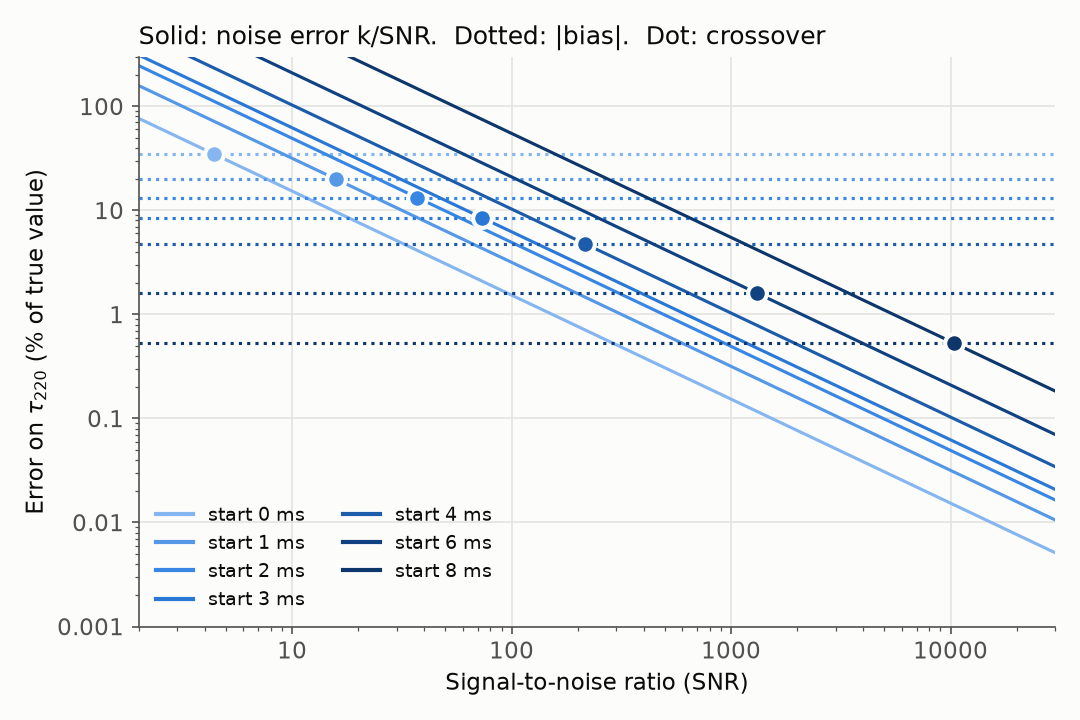

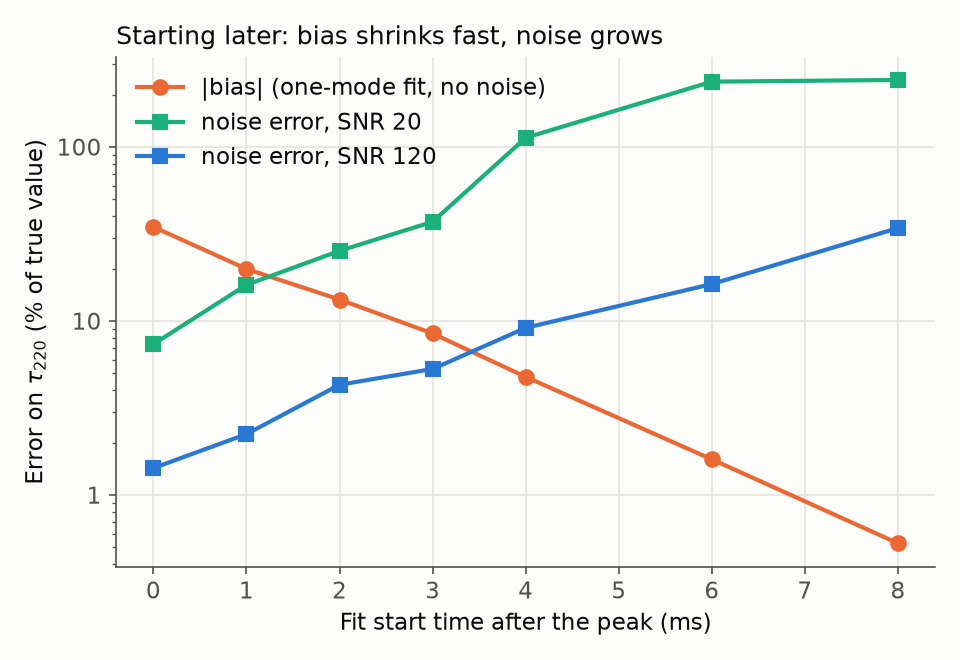

In [8]:
display(Image(ROOT / "figures" / "03_bias_vs_noise_crossover.png"))
display(Image(ROOT / "figures" / "04_bias_and_noise_vs_start.png"))

## What I found

